# Black Holes, Relativity, Gravitational Time Dilation, and the Possibility of Returning to Earth

**Research notebook — two investigations**

1. **Closest theoretical candidate:** Which *cataloged, confirmed* black hole is nearest to Earth and allows a chosen static gravitational clock-rate difference at some radius outside the event horizon?
2. **Closest human-feasibility candidate:** Which cataloged object can showcase an observable clock-rate difference while meeting explicitly modeled tidal and acceleration constraints? What changes when a spacecraft orbits instead of hovers?

**Scope and warning.** This is an purely research, with reproducible model. I am to model isolated, nonrotating, uncharged (Schwarzschild) black holes. Accretion radiation, jets, spin, external gravitational fields, navigation, propulsion, fuel, life support, and actual interstellar travel are not modeled in this notebook. A positive result means *passes the stated model*, **not** that human travel is feasible. The catalog is a curated demonstration sample, **not all known black holes**; rankings are valid only within the included rows. For a literature-grade all-known search, replace the CSV with a systematically assembled catalog and record provenance and uncertainty for each measurement.

In [1]:
#%pip install numpy pandas matplotlib astropy scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from astropy import units as u, constants as const

G, c, M_sun = const.G, const.c, const.M_sun
plt.rcParams.update({'figure.figsize': (9, 5.5), 'axes.grid': True, 'grid.alpha': .25})
pd.set_option('display.max_columns', 30)
print('Libraries ready.')

Libraries ready.


## 1. Definitions and physics

For an isolated Schwarzschild black hole of mass $M$, the event-horizon radius is

$$r_s=2GM/c^2.$$

A **stationary** (hovering) clock at Schwarzschild coordinate radius $r>r_s$ ticks relative to a clock stationary at infinity as

$$q_{\rm static}=\frac{d\tau}{dt}=\sqrt{1-r_s/r}.$$

Define **fractional time loss** $\epsilon=1-q$. The radius for a specified loss is

$$r_{\rm target}=\frac{r_s}{1-(1-\epsilon)^2}=\frac{r_s}{\epsilon(2-\epsilon)}.$$

**Note:** $r$ is measured from the center in Schwarzschild coordinates, not altitude above the horizon. At fixed $r/r_s$, the static clock-rate ratio is independent of mass. At fixed physical distance, mass matters. Schwarzschild $t$ is the time of an idealized stationary observer at infinity, not automatically the elapsed time on Earth.

For a freely moving **circular geodesic**, the clock-rate relative to Schwarzschild coordinate time is

$$q_{\rm orbit}=\sqrt{1-3GM/(rc^2)}=\sqrt{1-3r_s/(2r)}.$$

Timelike circular orbits exist for $r>1.5r_s$; **stable** circular geodesics require $r\ge 3r_s$ (the ISCO). Thus the smallest clock rate on a stable Schwarzschild circular geodesic is $1/\sqrt 2\approx0.7071$.

In [3]:
def rs(M):
    return (2*G*M/c**2).to(u.m)

def q_static(r, M):
    z = (rs(M)/r).decompose().value
    return np.where(z < 1, np.sqrt(np.maximum(0, 1-z)), np.nan)

def q_orbit(r, M):
    x = (rs(M) / r).decompose().value

    # Stable circular Schwarzschild orbits exist at r >= 3*r_s
    valid = x <= (1/3 + 1e-12)

    return np.where(
        valid,
        np.sqrt(np.maximum(0, 1 - 1.5*x)),
        np.nan
    )

def r_for_loss(eps, M):
    if not 0 < eps < 1: raise ValueError('loss must lie strictly between 0 and 1')
    return rs(M)/(eps*(2-eps))

def tidal_delta_a(r, M, height=1.8*u.m):
    # Newtonian radial differential acceleration, useful as a leading-order local tidal scale
    return (2*G*M*height/r**3).to(u.m/u.s**2)

def hover_proper_a(r, M):
    # Proper acceleration required to hover, divergent at the horizon
    x = (rs(M)/r).decompose().value
    return (G*M/r**2 / np.sqrt(1-x)).to(u.m/u.s**2)

assert np.isclose(q_static(10*rs(10*M_sun),10*M_sun), np.sqrt(.9))
assert np.isclose(q_orbit(3*rs(10*M_sun),10*M_sun), 1/np.sqrt(2))
print('Sanity checks passed.')

Sanity checks passed.


## 2. Your original 6.7 AU question: fixed distance versus fixed horizon multiple

$10^{12}$ meters is approximately 6.6846 AU. This is a **comparison distance**, not a physically privileged black-hole scale. For very massive black holes, that coordinate radius is inside the horizon, where the stationary-clock formula does not apply.

In [4]:
demo = {
    'Stellar 10 M☉': 10,
    'Cygnus X-1 (~21 M☉)': 21,
    'Sgr A* (~4.3 million M☉)': 4.3e6,
    'M87* (~6.5 billion M☉)': 6.5e9
}

# Compare two gravitational time dilation targets
targets = [0.25, 0.50]

rows = []

for name, solar in demo.items():
    mass = solar * M_sun
    r_s = rs(mass)

    for loss in targets:
        # Required radius for a stationary observer
        r = r_for_loss(loss, mass)

        # Tidal acceleration across a 1.8m human
        tidal = tidal_delta_a(r, mass)

        # Proper acceleration required to hover
        hover = hover_proper_a(r, mass)

        rows.append({
            'Black Hole': name,
            'Mass (M☉)': solar,
            'Time Dilation Loss': f'{loss:.0%}',
            'Radius (r_s)': (r / r_s).decompose().value,
            'Distance from Center (km)': r.to_value(u.km),
            'Height Above Horizon (km)': (r-r_s).to_value(u.km),
            'Tidal Accel (g)': tidal.to_value(u.m/u.s**2) / 9.80665,
            'Hover Accel (g)': hover.to_value(u.m/u.s**2) / 9.80665,
            'Stable Circular Orbit': bool(r >= 3*r_s)
        })

results = pd.DataFrame(rows)

display(results.round(3))


,Black Hole,Mass (M☉),Time Dilation Loss,Radius (r_s),Distance from Center (km),Height Above Horizon (km),Tidal Accel (g),Hover Accel (g),Stable Circular Orbit
0,Stellar 10 M☉,1.000000e+01,25%,2.286,6.750300e+01,3.797000e+01,1583897.086,3.959910e+10,False
1,Stellar 10 M☉,1.000000e+01,50%,1.333,3.937700e+01,9.844000e+00,7979516.515,1.745593e+11,False
2,Cygnus X-1 (~21 M☉),2.100000e+01,25%,2.286,1.417560e+02,7.973800e+01,359160.337,1.885672e+10,False
3,Cygnus X-1 (~21 M☉),2.100000e+01,50%,1.333,8.269100e+01,2.067300e+01,1809414.176,8.312348e+10,False
4,Sgr A* (~4.3 million M☉),4.300000e+06,25%,2.286,2.902623e+07,1.632725e+07,0.000,9.209094e+04,False
5,Sgr A* (~4.3 million M☉),4.300000e+06,50%,1.333,1.693197e+07,4.232992e+06,0.000,4.059519e+05,False
6,M87* (~6.5 billion M☉),6.500000e+09,25%,2.286,4.387686e+10,2.468073e+10,0.000,6.092200e+01,False
7,M87* (~6.5 billion M☉),6.500000e+09,50%,1.333,2.559483e+10,6.398708e+09,0.000,2.685530e+02,False


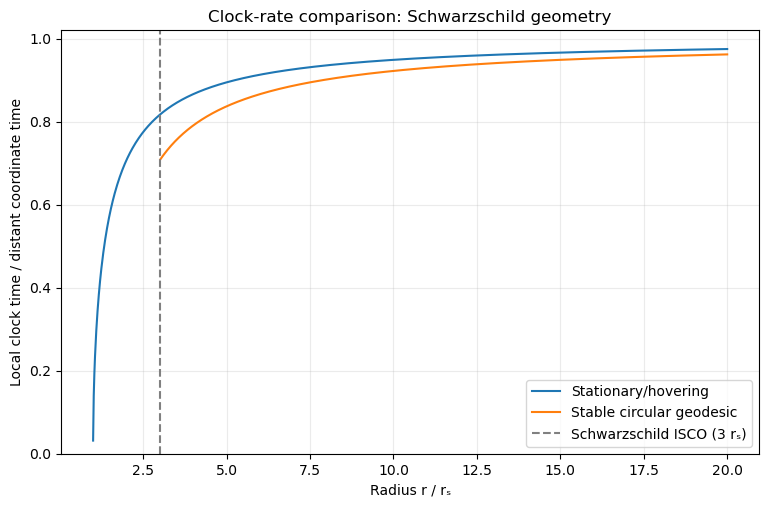

In [5]:
x=np.linspace(1.001,20,1000)
fig,ax=plt.subplots()
ax.plot(x,np.sqrt(1-1/x),label='Stationary/hovering')
xo=x[x>=3]
ax.plot(xo,np.sqrt(1-1.5/xo),label='Stable circular geodesic')
ax.axvline(3,color='gray',linestyle='--',label='Schwarzschild ISCO (3 rₛ)')
ax.set(xlabel='Radius r / rₛ',ylabel='Local clock time / distant coordinate time',ylim=(0,1.02),title='Clock-rate comparison: Schwarzschild geometry')
ax.legend();plt.show()

## 3. Catalog and provenance

The starter file below uses **rounded illustrative literature values**, not a verified 2026 census. Approximate numbers can change as measurements improve. The `confirmed` flag is a *working screening designation*; uncertain intermediate-mass candidates are excluded from the confirmed ranking. Do not interpret absence from this table as absence from the universe.

Starter reading / primary source discovery:
- Gaia BH1 and BH2: El-Badry et al. (2023), *A Sun-like star orbiting a black hole* and Gaia BH2 follow-up: [arXiv search](https://arxiv.org/search/?query=Gaia+BH1+El-Badry&searchtype=all).
- Gaia BH3: ESA Gaia collaboration discovery announcement and related publication: [ESA Gaia](https://www.esa.int/Science_Exploration/Space_Science/Gaia).
- Galactic-center mass and distance: GRAVITY Collaboration: [ESO GRAVITY](https://www.eso.org/public/science/gravity/).
- M87*: Event Horizon Telescope Collaboration (2019): [EHT publications](https://eventhorizontelescope.org/publications).
- Omega Centauri candidate: Häberle et al. (2024) and subsequent debate: [arXiv search](https://arxiv.org/search/?query=Omega+Centauri+intermediate+mass+black+hole&searchtype=all).

**Before publication:** verify each row against its specific measurement paper, add uncertainty intervals, epoch, method, DOI, and confidence classification. No exhaustive catalog or real-time source verification is performed here.

In [6]:
catalog_path=Path('black_holes.csv')
starter=[
 {'name':'Gaia BH1','mass_msun':9.6,'distance_ly':1560,'confirmed':True,'environment':'quiet stellar binary','reference':'El-Badry et al. 2023; approximate'},
 {'name':'Gaia BH2','mass_msun':8.9,'distance_ly':3800,'confirmed':True,'environment':'stellar binary','reference':'Gaia BH2 discovery; approximate'},
 {'name':'Gaia BH3','mass_msun':33,'distance_ly':1926,'confirmed':True,'environment':'stellar binary','reference':'Gaia collaboration 2024; approximate'},
 {'name':'Cygnus X-1','mass_msun':21,'distance_ly':7200,'confirmed':True,'environment':'X-ray binary; radiation hazard','reference':'Miller-Jones et al. 2021; approximate'},
 {'name':'Sagittarius A*','mass_msun':4.3e6,'distance_ly':26000,'confirmed':True,'environment':'Galactic center; complex environment','reference':'GRAVITY Collaboration; approximate'},
 {'name':'Omega Centauri candidate','mass_msun':4e4,'distance_ly':17700,'confirmed':False,'environment':'dense star cluster; disputed IMBH','reference':'Haeberle et al. 2024; assumed candidate mass'},
 {'name':'M87*','mass_msun':6.5e9,'distance_ly':53.5e6,'confirmed':True,'environment':'active galactic nucleus; jet','reference':'EHT Collaboration 2019; approximate'}]
if not catalog_path.exists():
    pd.DataFrame(starter).to_csv(catalog_path,index=False)
catalog=pd.read_csv(catalog_path)
required={'name','mass_msun','distance_ly','confirmed','environment','reference'}
assert required.issubset(catalog.columns)
assert (catalog[['mass_msun','distance_ly']]>0).all().all()
catalog['confirmed']=catalog.confirmed.astype(str).str.lower().map({'true':True,'false':False})
assert catalog.confirmed.notna().all(), 'confirmed must be True or False'
assert catalog.name.is_unique
print(f'Loaded {len(catalog)} objects from {catalog_path.resolve()}')
display(catalog.sort_values('distance_ly'))

Loaded 7 objects from /Users/adamel-kadi/black_holes.csv


,name,mass_msun,distance_ly,confirmed,environment,reference
0,Gaia BH1,9.600000e+00,1560.0,True,quiet stellar binary,El-Badry et al. 2023; approximate
2,Gaia BH3,3.300000e+01,1926.0,True,stellar binary,Gaia collaboration 2024; approximate
1,Gaia BH2,8.900000e+00,3800.0,True,stellar binary,Gaia BH2 discovery; approximate
3,Cygnus X-1,2.100000e+01,7200.0,True,X-ray binary; radiation hazard,Miller-Jones et al. 2021; approximate
5,Omega Centauri candidate,4.000000e+04,17700.0,False,dense star cluster; disputed IMBH,Haeberle et al. 2024; assumed candidate mass
4,Sagittarius A*,4.300000e+06,26000.0,True,Galactic center; complex environment,GRAVITY Collaboration; approximate
6,M87*,6.500000e+09,53500000.0,True,active galactic nucleus; jet,EHT Collaboration 2019; approximate


## 4. Experiment A — closest theoretical candidate

Choose a fractional static clock-rate loss. A radius with $r>r_s$ exists for *every* positive black hole mass and every $0<\epsilon<1$. **Consequently, under the horizon-only criterion, the nearest confirmed cataloged black hole always wins, independent of the chosen loss threshold.** This is a mathematically valid but weak definition of 'accessible'; the required hovering force can be lethal.

In [8]:
LOSS=0.250              # 25% slower stationary clock
HUMAN_HEIGHT=1.8*u.m
TIDAL_LIMIT=10*u.m/u.s**2   # illustrative differential-acceleration cutoff, not a clinical safety standard
HOVER_LIMIT=3*const.g0      # illustrative sustained-acceleration cutoff, not a clinical safety standard

def evaluate(df, loss=LOSS):
    result=df.copy()
    m=result.mass_msun.to_numpy()*M_sun
    rr=r_for_loss(loss,m)
    result['rs_km']=rs(m).to_value(u.km)
    result['target_radius_km']=rr.to_value(u.km)
    result['target_radius_over_rs']=rr.to_value(u.m)/rs(m).to_value(u.m)
    result['tidal_m_s2']=tidal_delta_a(rr,m,HUMAN_HEIGHT).to_value(u.m/u.s**2)
    result['hover_accel_g']=hover_proper_a(rr,m).to_value(u.m/u.s**2)/const.g0.to_value(u.m/u.s**2)
    result['tidal_pass']=result.tidal_m_s2<=TIDAL_LIMIT.to_value(u.m/u.s**2)
    result['hover_pass']=result.hover_accel_g<=HOVER_LIMIT.to_value(u.m/u.s**2)/const.g0.to_value(u.m/u.s**2)
    result['static_screen_pass']=result.tidal_pass & result.hover_pass
    return result

screen=evaluate(catalog)
confirmed=screen[screen.confirmed].sort_values('distance_ly')
display(confirmed[['name','distance_ly','mass_msun','target_radius_km','tidal_m_s2','hover_accel_g','static_screen_pass']].round(5))
print('Nearest confirmed in sample (horizon-only):',confirmed.iloc[0]['name'])

,name,distance_ly,mass_msun,target_radius_km,tidal_m_s2,hover_accel_g,static_screen_pass
0,Gaia BH1,1560.0,9.600000e+00,6.480274e+01,1.685408e+07,4.124907e+10,False
2,Gaia BH3,1926.0,3.300000e+01,2.227594e+02,1.426329e+06,1.199973e+10,False
1,Gaia BH2,3800.0,8.900000e+00,6.007754e+01,1.960955e+07,4.449338e+10,False
3,Cygnus X-1,7200.0,2.100000e+01,1.417560e+02,3.522160e+06,1.885672e+10,False
4,Sagittarius A*,26000.0,4.300000e+06,2.902623e+07,8.000000e-05,9.209094e+04,False
6,M87*,53500000.0,6.500000e+09,4.387686e+10,0.000000e+00,6.092170e+01,False


Nearest confirmed in sample (horizon-only): Gaia BH1


## 5. Experiment B — human-feasibility screening

The leading-order radial tidal acceleration across body length $L$ is $\Delta a\approx2GML/r^3$. This is a **local tidal scale**, not a full injury model. The proper acceleration to **hover** is

$$a_{\rm hover}=\frac{GM}{r^2\sqrt{1-r_s/r}}.$$

It diverges at the horizon. The limits below are **illustrative adjustable assumptions**; there is no universally established human-safe value for the combined stresses, durations, radiation, and mission profile. Even a candidate that passes both tests is **not certified survivable**.

In [9]:
display(screen.sort_values('distance_ly')[['name','confirmed','distance_ly','tidal_m_s2','hover_accel_g','tidal_pass','hover_pass','static_screen_pass']].round(6))
qualified=screen[screen.confirmed & screen.static_screen_pass].sort_values('distance_ly')
if qualified.empty:
    print('No confirmed cataloged black hole passes BOTH illustrative hovering and tidal constraints.')
else:
    print('Nearest confirmed passing the simplified static screen:',qualified.iloc[0]['name'])
print('Important: passing this screen does not establish plausible spacecraft travel or human survivability.')

,name,confirmed,distance_ly,tidal_m_s2,hover_accel_g,tidal_pass,hover_pass,static_screen_pass
0,Gaia BH1,True,1560.0,1.685408e+07,4.124907e+10,False,False,False
2,Gaia BH3,True,1926.0,1.426329e+06,1.199973e+10,False,False,False
1,Gaia BH2,True,3800.0,1.960955e+07,4.449338e+10,False,False,False
3,Cygnus X-1,True,7200.0,3.522160e+06,1.885672e+10,False,False,False
5,Omega Centauri candidate,False,17700.0,9.707950e-01,9.899776e+06,True,False,False
4,Sagittarius A*,True,26000.0,8.400000e-05,9.209094e+04,True,False,False
6,M87*,True,53500000.0,0.000000e+00,6.092170e+01,True,False,False


No confirmed cataloged black hole passes BOTH illustrative hovering and tidal constraints.
Important: passing this screen does not establish plausible spacecraft travel or human survivability.


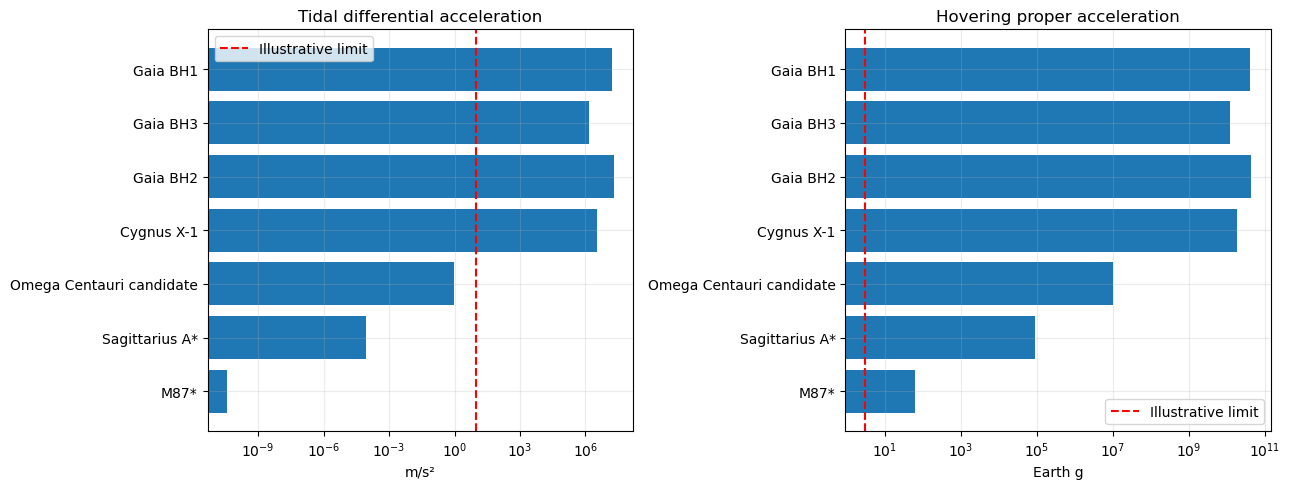

In [16]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
ordered=screen.sort_values('distance_ly')
for ax,col,lim,title in [(axes[0],'tidal_m_s2',TIDAL_LIMIT.to_value(u.m/u.s**2),'Tidal differential acceleration'),
                         (axes[1],'hover_accel_g',HOVER_LIMIT.to_value(u.m/u.s**2)/const.g0.to_value(u.m/u.s**2),'Hovering proper acceleration')]:
    ax.barh(ordered.name,ordered[col].clip(lower=1e-15))
    ax.axvline(lim,color='red',ls='--',label='Illustrative limit')
    ax.set_xscale('log');ax.set_xlabel('m/s²' if col=='tidal_m_s2' else 'Earth g');ax.set_title(title);ax.legend()
axes[0].invert_yaxis();axes[1].invert_yaxis();plt.tight_layout();plt.show()

## 6. Stable circular orbit alternative

A spacecraft in a stable circular geodesic needs **no continuous rocket thrust** to maintain the idealized orbit, and its occupants are locally weightless. This does **not** remove tidal forces or the hazards of arriving, leaving, or traversing the black-hole environment.

For stable Schwarzschild circular orbits $r\ge3r_s$, the maximum time loss relative to coordinate time at infinity is $1-1/\sqrt2\approx29.29\%$. A 50% loss is **not possible** on such an orbit. For a chosen target $q=1-\epsilon$, solve $r/r_s=1.5/(1-q^2)$ and require $r/r_s\ge3$.

In [11]:
MAX_STABLE_LOSS=1-1/np.sqrt(2)
def stable_orbit_radius(loss,M):
    if not 0<loss<1: raise ValueError('loss must be in (0,1)')
    if loss>MAX_STABLE_LOSS+1e-12: return None
    q=1-loss
    return 1.5*rs(M)/(1-q*q)

orbit_rows=[]
for _,row in catalog.iterrows():
    m=row.mass_msun*M_sun
    rr=stable_orbit_radius(LOSS,m)
    orbit_rows.append({'name':row['name'],'confirmed':row.confirmed,'distance_ly':row.distance_ly,
                       'orbit_r_over_rs':np.nan if rr is None else (rr/rs(m)).decompose().value,
                       'orbit_r_km':np.nan if rr is None else rr.to_value(u.km),
                       'orbit_tidal_m_s2':np.nan if rr is None else tidal_delta_a(rr,m,HUMAN_HEIGHT).to_value(u.m/u.s**2),
                       'stable_orbit_screen_pass':False if rr is None else bool(tidal_delta_a(rr,m,HUMAN_HEIGHT)<=TIDAL_LIMIT)})
orbits=pd.DataFrame(orbit_rows).sort_values('distance_ly')
display(orbits.round(6))
viable_orbits=orbits[orbits.confirmed & orbits.stable_orbit_screen_pass]
print('Closest confirmed object passing stable-orbit + illustrative tidal screen:',
      viable_orbits.iloc[0]['name'] if len(viable_orbits) else 'None in sample')

,name,confirmed,distance_ly,orbit_r_over_rs,orbit_r_km,orbit_tidal_m_s2,stable_orbit_screen_pass
0,Gaia BH1,True,1560.0,3.428571,9.720412e+01,4.993803e+06,False
2,Gaia BH3,True,1926.0,3.428571,3.341392e+02,4.226160e+05,False
1,Gaia BH2,True,3800.0,3.428571,9.011632e+01,5.810237e+06,False
3,Cygnus X-1,True,7200.0,3.428571,2.126340e+02,1.043603e+06,False
5,Omega Centauri candidate,False,17700.0,3.428571,4.050172e+05,2.876430e-01,True
4,Sagittarius A*,True,26000.0,3.428571,4.353934e+07,2.500000e-05,True
6,M87*,True,53500000.0,3.428571,6.581529e+10,0.000000e+00,True


Closest confirmed object passing stable-orbit + illustrative tidal screen: Sagittarius A*


## 7. Sensitivity: what changes as the target time dilation increases?

Compare horizon-only, static-hovering screen, and stable-orbit screen across several thresholds. **Do not combine hovering and orbiting results into a single physical scenario.**

In [12]:
sensitivity=[]
for loss in [.01,.05,.10,.20,.25,.29,.50,.90]:
    s=evaluate(catalog,loss)
    st=s[s.confirmed & s.static_screen_pass].sort_values('distance_ly')
    orbit_ok=[]
    for _,v in catalog[catalog.confirmed].iterrows():
        rr=stable_orbit_radius(loss,v.mass_msun*M_sun)
        if rr is not None and tidal_delta_a(rr,v.mass_msun*M_sun,HUMAN_HEIGHT)<=TIDAL_LIMIT:
            orbit_ok.append((v.distance_ly,v['name']))
    sensitivity.append({'time_loss_pct':loss*100,'nearest_horizon_only':confirmed.iloc[0]['name'],
                        'nearest_static_screen':st.iloc[0]['name'] if len(st) else None,
                        'nearest_stable_orbit_screen':min(orbit_ok)[1] if orbit_ok else None})
display(pd.DataFrame(sensitivity))

,time_loss_pct,nearest_horizon_only,nearest_static_screen,nearest_stable_orbit_screen
0,1.0,Gaia BH1,M87*,Sagittarius A*
1,5.0,Gaia BH1,M87*,Sagittarius A*
2,10.0,Gaia BH1,None,Sagittarius A*
3,20.0,Gaia BH1,None,Sagittarius A*
4,25.0,Gaia BH1,None,Sagittarius A*
5,29.0,Gaia BH1,None,Sagittarius A*
6,50.0,Gaia BH1,None,None
7,90.0,Gaia BH1,None,None


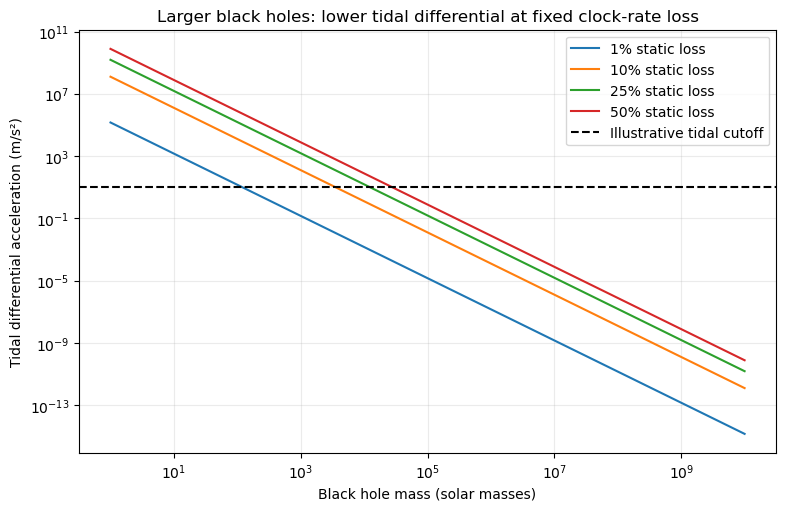

In [13]:
masses=np.logspace(0,10,450)*M_sun
fig,ax=plt.subplots()
for loss in [.01,.10,.25,.50]:
    r=r_for_loss(loss,masses)
    ax.loglog((masses/M_sun).decompose().value,tidal_delta_a(r,masses,HUMAN_HEIGHT).value,label=f'{loss:.0%} static loss')
ax.axhline(TIDAL_LIMIT.value,ls='--',color='black',label='Illustrative tidal cutoff')
ax.set(xlabel='Black hole mass (solar masses)',ylabel='Tidal differential acceleration (m/s²)',title='Larger black holes: lower tidal differential at fixed clock-rate loss')
ax.legend();plt.show()

## 8. Return-to-Earth thought experiment — explicit toy assumptions

The following **is not a relativistic trajectory solver**. It illustrates the dominant challenge: interstellar distance. Assume straight-line travel at a constant fraction $\beta$ of light speed between Earth and the black hole, with instantaneous acceleration/deceleration, no gravity during transit, and no complications from orbit insertion or escape. We approximate the Earth-frame travel time by $2D/(\beta c)$, the traveler’s transit proper time by that amount divided by $\gamma$, and the dwell time near the black hole by $T_{\rm dwell,Earth}\,q$. This uses a remote Schwarzschild coordinate time as a proxy for Earth time and is only a rough illustration, especially for distant galactic environments.

The **travel segment** includes special-relativistic time dilation; the **dwell segment** uses the static or circular-orbit clock-rate factor. We do not add separate velocity and gravitational time dilation factors at the same location: the orbit equation already incorporates both for a circular geodesic.

In [14]:
def illustrative_roundtrip(distance_ly, beta, dwell_earth_years, local_q):
    if not (0<beta<1): raise ValueError('beta must be between 0 and 1')
    if not (0<local_q<=1): raise ValueError('clock ratio must be in (0,1]')
    gamma=1/np.sqrt(1-beta**2)
    earth_transit_yr=2*distance_ly/beta  # by definition 1 ly / c = 1 year
    traveler_transit_yr=earth_transit_yr/gamma
    return {'Earth_elapsed_years':earth_transit_yr+dwell_earth_years,
            'Traveler_elapsed_years':traveler_transit_yr+local_q*dwell_earth_years,
            'Earth_minus_traveler_years':earth_transit_yr+dwell_earth_years-traveler_transit_yr-local_q*dwell_earth_years,
            'gamma_transit':gamma}

BETA=.90
DWELL_EARTH_YEARS=1.0
examples=[]
for _,v in catalog[catalog.confirmed].sort_values('distance_ly').iterrows():
    examples.append({'name':v['name'],'distance_ly':v.distance_ly,**illustrative_roundtrip(v.distance_ly,BETA,DWELL_EARTH_YEARS,1-LOSS)})
display(pd.DataFrame(examples).round(2))
print('Toy model ignores acceleration time, fuel, orbit capture, radiation, and real mission feasibility.')

,name,distance_ly,Earth_elapsed_years,Traveler_elapsed_years,Earth_minus_traveler_years,gamma_transit
0,Gaia BH1,1560.0,3.467670e+03,1511.83,1955.83,2.29
1,Gaia BH3,1926.0,4.281000e+03,1866.36,2414.64,2.29
2,Gaia BH2,3800.0,8.445440e+03,3681.60,4763.85,2.29
3,Cygnus X-1,7200.0,1.600100e+04,6974.99,9026.01,2.29
4,Sagittarius A*,26000.0,5.777878e+04,25185.50,32593.28,2.29
5,M87*,53500000.0,1.188889e+08,51822465.97,67066423.92,2.29


Toy model ignores acceleration time, fuel, orbit capture, radiation, and real mission feasibility.


## 9. Optional: local time versus distant time at one target

For a fixed stationary observer, $\tau=q t$ for a period during which $q$ is constant. This chart makes the interpretation concrete; it does **not** model a journey.

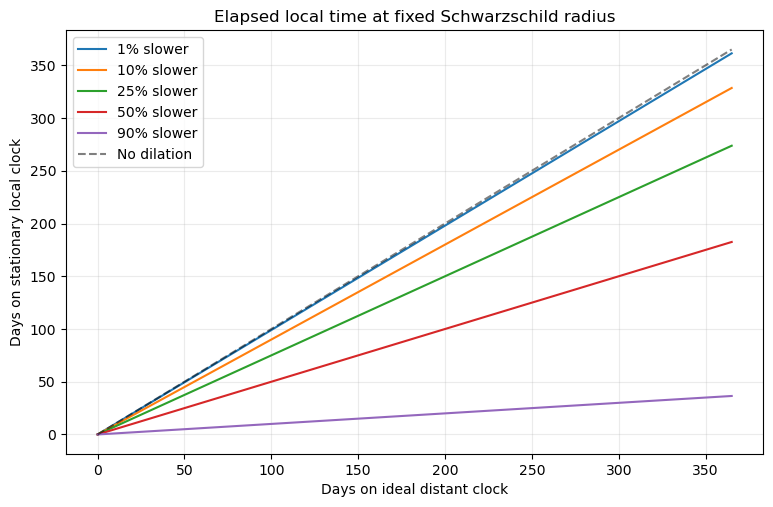

In [15]:
distant_days=np.linspace(0,365,366)
fig,ax=plt.subplots()
for loss in [.01,.10,.25,.50,.90]:
    ax.plot(distant_days,(1-loss)*distant_days,label=f'{loss:.0%} slower')
ax.plot(distant_days,distant_days,'k--',alpha=.5,label='No dilation')
ax.set(xlabel='Days on ideal distant clock',ylabel='Days on stationary local clock',title='Elapsed local time at fixed Schwarzschild radius')
ax.legend();plt.show()

## 10. Findings, limitations, and next research tasks

**What the notebook establishes mathematically:**

- Any positive-mass Schwarzschild black hole has a radius outside the horizon where a static clock has any chosen $0<q<1$. Thus a **horizon-only** ranking simply ranks black holes by distance from Earth.
- At a fixed fraction of $r_s$, stationary time dilation does not depend on mass. At a fixed physical distance, it does.
- Tidal differential acceleration falls strongly with increasing black hole mass at fixed $r/r_s$; however, hovering acceleration must be evaluated separately.
- Stable Schwarzschild circular geodesics cannot produce more than about 29.29% time loss relative to infinity.
- Passing tidal and orbit screening is **not proof of human survivability**, nor of the ability to reach and return from the object.

**What is still needed to answer 'of all known black holes' rigorously:**

1. Assemble a comprehensive, versioned catalog with distances, masses, error bars, confirmation status, and source DOIs. Include completeness and selection-bias caveats. The starter CSV is **not exhaustive**.
2. Recalculate rankings with Monte Carlo draws from measured mass/distance uncertainties; quantify how often each object ranks first.
3. Include black-hole spin (Kerr geometry), orbit inclination, radiation/accretion, surrounding stars, and trajectory/capture/escape constraints.
4. Model a genuine inbound/outbound relativistic trajectory (numerical geodesics or controlled rocket trajectories), rather than the instantaneous-acceleration transit toy model.
5. State whether comparisons use Earth clocks, clocks at infinity, or another observer; use appropriate spacetime model and reference clock.